# Exploratory Data Analysis - Visualization

Six matplotlib/seaborn plots: payload vs outcome scatter, yearly success trend, site counts, success rate by orbit, payload distribution by orbit, reuse vs success.

**Outputs:** `plots/eda_*.png`

```text
Exploratory Data Analysis - matplotlib / seaborn charts
Outputs: plots/eda_*.png
```

In [1]:
import os, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

BASE = os.path.abspath(".")
PLOTS = os.path.join(BASE, "plots")
os.makedirs(PLOTS, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 150

df = pd.read_csv(os.path.join(BASE, "data", "dataset_part_2.csv"))

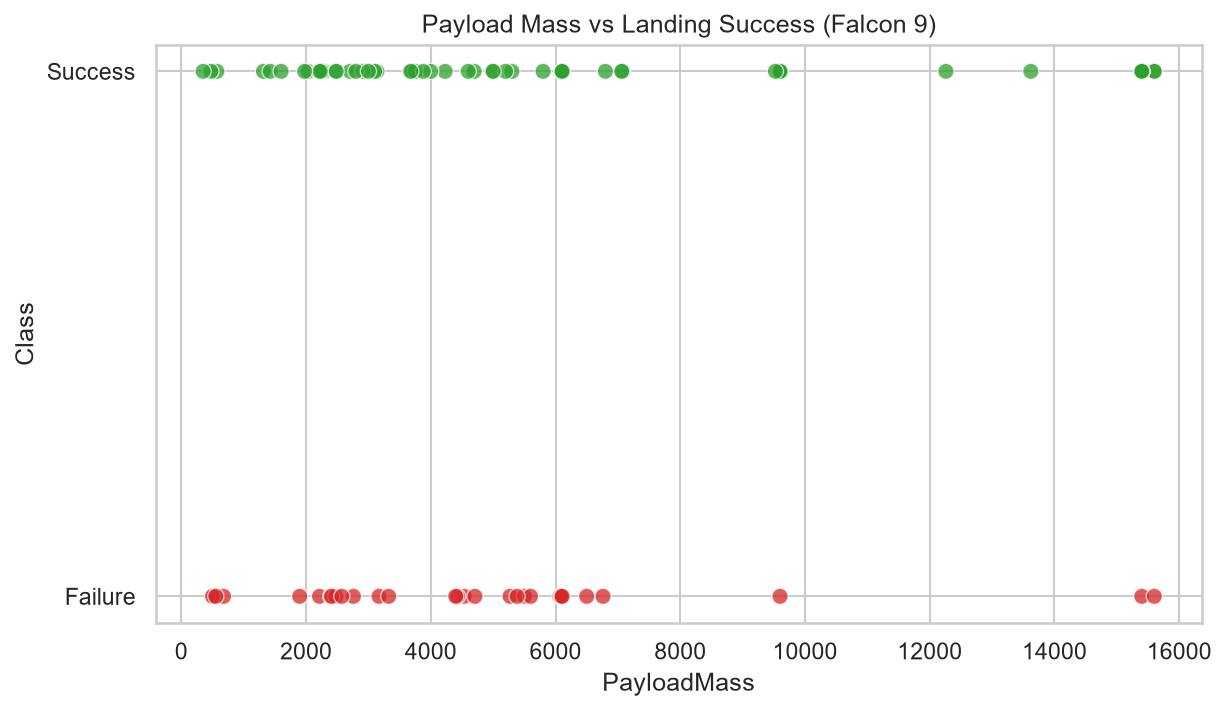

In [2]:
# 1. Payload vs launch success scatter
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df[df.BoosterVersion == "Falcon 9"],
                x="PayloadMass", y="Class", hue="Class", palette={0: "#d62728", 1: "#2ca02c"},
                s=60, alpha=0.75, legend=False)
plt.yticks([0, 1], ["Failure", "Success"])
plt.title("Payload Mass vs Landing Success (Falcon 9)")
plt.savefig(os.path.join(PLOTS, "eda_payload_scatter.png"), bbox_inches="tight")

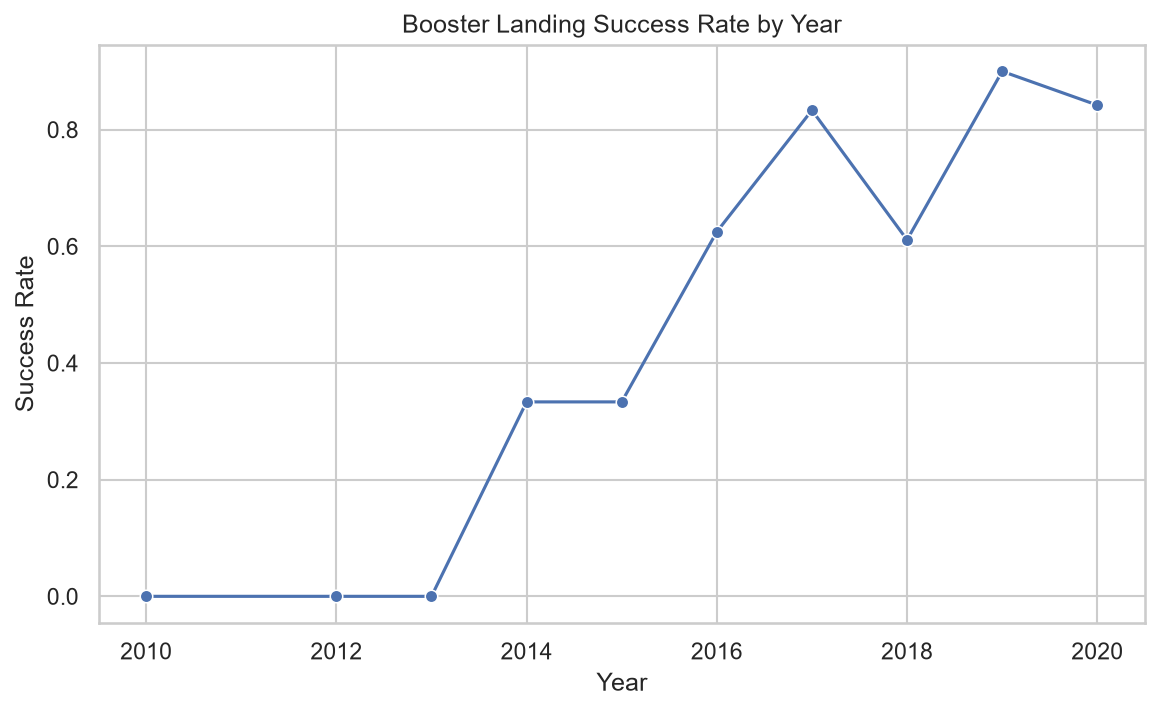

In [3]:
# 2. Overall success rate over years
plt.figure(figsize=(9, 5))
yearly = df.groupby("Year")["Class"].mean().reset_index()
sns.lineplot(data=yearly, x="Year", y="Class", marker="o")
plt.title("Booster Landing Success Rate by Year")
plt.ylabel("Success Rate")
plt.savefig(os.path.join(PLOTS, "eda_success_by_year.png"), bbox_inches="tight")

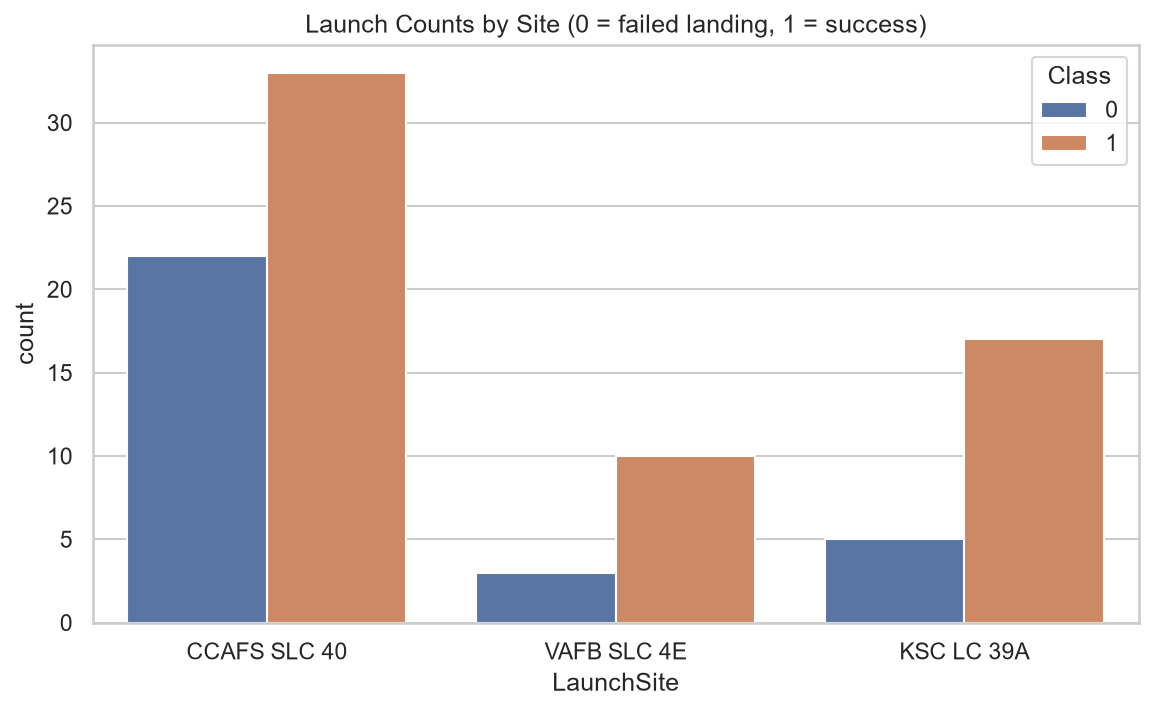

In [4]:
# 3. Launch site bar chart (counts)
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="LaunchSite", hue="Class")
plt.title("Launch Counts by Site (0 = failed landing, 1 = success)")
plt.savefig(os.path.join(PLOTS, "eda_site_counts.png"), bbox_inches="tight")

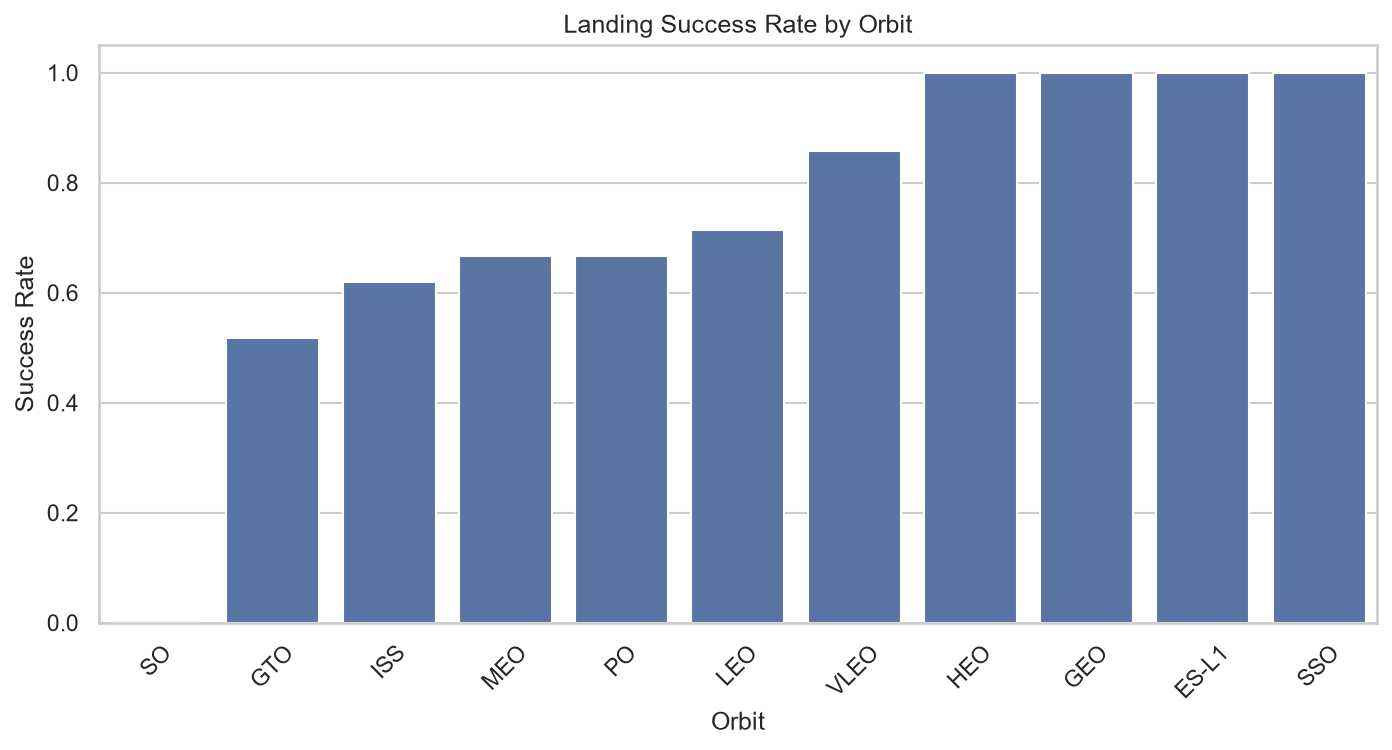

In [5]:
# 4. Success rate by orbit
plt.figure(figsize=(11, 5))
orbit = df.groupby("Orbit")["Class"].agg(["count", "mean"]).reset_index().sort_values("mean")
sns.barplot(data=orbit, x="Orbit", y="mean")
plt.xticks(rotation=45)
plt.title("Landing Success Rate by Orbit")
plt.ylabel("Success Rate")
plt.savefig(os.path.join(PLOTS, "eda_orbit_success.png"), bbox_inches="tight")

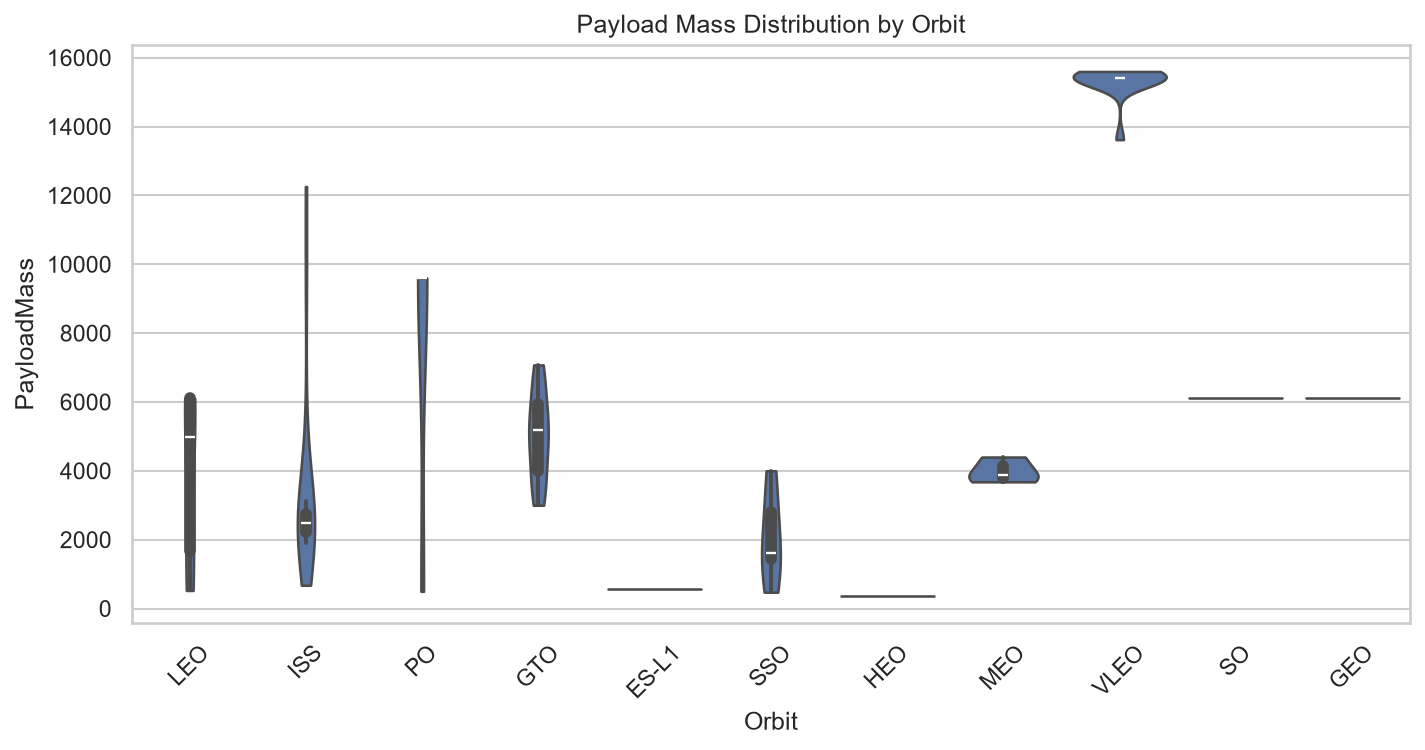

In [6]:
# 5. Payload mass distribution by orbit (violin)
plt.figure(figsize=(11, 5))
sns.violinplot(data=df[df.PayloadMass > 0], x="Orbit", y="PayloadMass", cut=0)
plt.xticks(rotation=45)
plt.title("Payload Mass Distribution by Orbit")
plt.savefig(os.path.join(PLOTS, "eda_payload_by_orbit.png"), bbox_inches="tight")

EDA plots saved: ['dash_dashboard_all.png', 'dash_dashboard_ksc.png', 'eda_flights_success.png', 'eda_orbit_success.png', 'eda_payload_by_orbit.png', 'eda_payload_scatter.png', 'eda_site_counts.png', 'eda_success_by_year.png', 'folium_launch_records_map.png', 'folium_launch_sites_map.png', 'folium_proximity_map.png', 'ml_confusion_matrix.png']


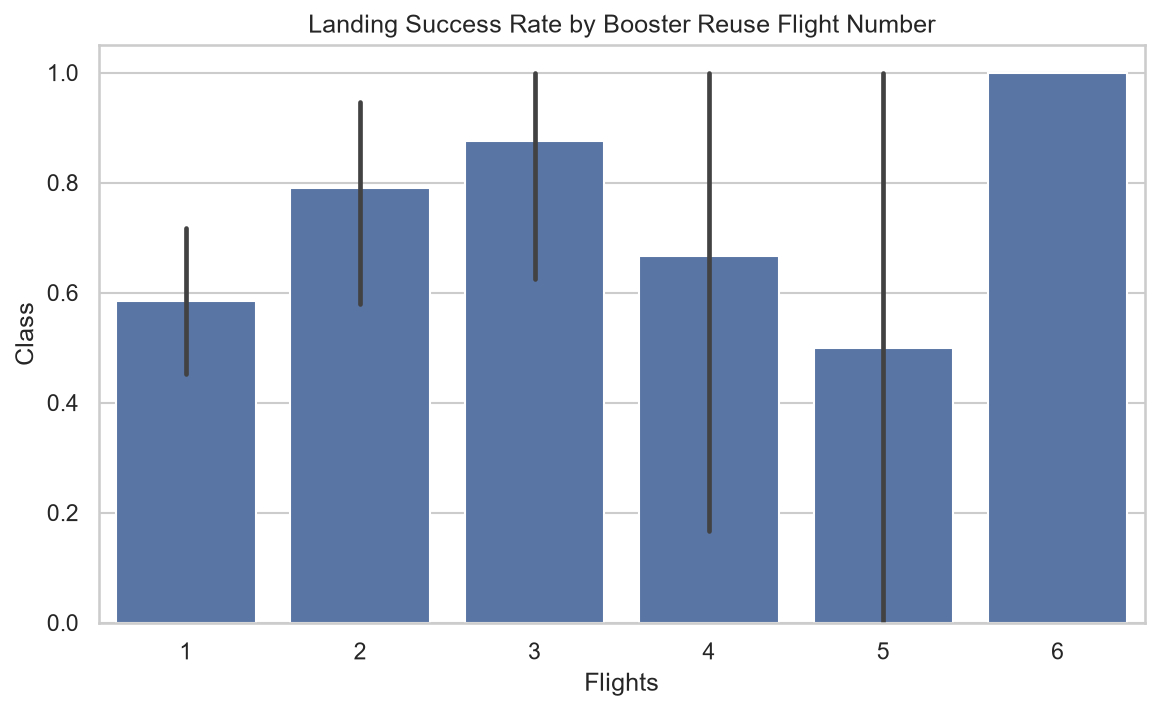

In [7]:
# 6. Flights (reuse) vs success
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="Flights", y="Class")
plt.title("Landing Success Rate by Booster Reuse Flight Number")
plt.savefig(os.path.join(PLOTS, "eda_flights_success.png"), bbox_inches="tight")

print("EDA plots saved:", sorted(os.listdir(PLOTS)))